# 06 · Ensemble Kalman filter: a 2D twin that learns its own physics
**Level: Advanced** · ~25 min · *Track: Data assimilation*

In 2D the Kalman filter of notebook 04 breaks down: a 48×48 field has 2,304 states, so $P$ has
5.3 million entries, and propagating it costs $O(n^3)$ per step. Worse, the unknown parameters
(diffusivity $\kappa$, pump strength $a$) enter the model **nonlinearly**.

The **ensemble Kalman filter (EnKF)** replaces $P$ with the spread of an ensemble of $N\approx 40$
model runs:

1. **Forecast:** run every member through the full nonlinear model, each with its own parameters.
2. **Analysis:** estimate covariances from the ensemble and apply the Kalman update to each member,
   using perturbed observations $y + \epsilon_i$.

$$P^f \approx \frac{1}{N-1}\sum_i (x_i - \bar x)(x_i-\bar x)^\top,\qquad x_i^a = x_i^f + K\,(y+\epsilon_i - Hx_i^f)$$

Because the parameters are stored in the ensemble's state vector (**state augmentation**), the
covariance between "concentration at the sensors" and "$\kappa$" updates the parameters, with no
adjoint and no gradient.

**Expert topics covered:** joint state-parameter estimation, covariance **inflation**,
**localization** (Gaspari-Cohn) against spurious long-range correlations, and the spread-skill check.

In [1]:
import sys; sys.path.insert(0, "..")
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML
from dtwin import viz
from dtwin.solvers import AdvDiff2D, gaussian_blob, random_blobs, smooth_noise
from dtwin.sensors import PointSensors, grid_2d, flat_to_xy
from dtwin.assimilation import EnKF, gaspari_cohn
viz.set_style()
rng = np.random.default_rng(11)

## 1. Reality and the twin's prior beliefs
* **Reality:** $\kappa^\star = 1.5\times10^{-3}$, $a^\star = 0.025$, an unknown initial contamination
  (random blobs), a known continuous inlet at $(0.2, 0.25)$ and a known removal rate $\lambda=0.03$.
* **Twin prior:** $\kappa\sim\text{LogNormal}(\log 6\times10^{-4},\,0.6)$, $a\sim\mathcal N(0.015, 0.007^2)$,
  and initial fields drawn from the same kind of random-blob distribution, but not the true one.
* **Sensors:** a 6×6 grid of probes, noise σ = 0.005, read once per time unit.

state size 2304, dt = 0.0109, 92 steps between observations


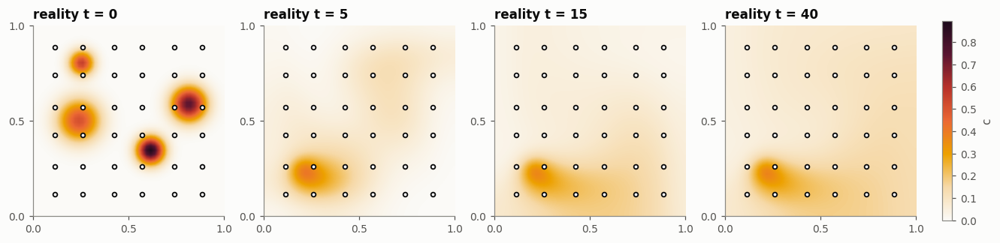

In [2]:
N_GRID, T_END, T_OBS = 48, 40.0, 1.0
KAPPA_TRUE, FLOW_TRUE = 1.5e-3, 0.025
model = AdvDiff2D(n=N_GRID, kappa=KAPPA_TRUE, flow_amplitude=FLOW_TRUE, decay=0.03,
                  kappa_max=5e-3, flow_max=0.06)
X, Y = model.X, model.Y
n_state = N_GRID**2
inlet = gaussian_blob(X, Y, 0.2, 0.25, width=0.04, amp=0.4)
steps_per_obs = int(round(T_OBS / model.dt))
n_cycles = int(round(T_END / T_OBS))

obs_idx, _ = grid_2d(N_GRID, 6)
sens = PointSensors(obs_idx, n_state, noise_std=0.005)
sx, sy = flat_to_xy(obs_idx, N_GRID, model.x)

c_true = random_blobs(X, Y, rng, n_blobs=4)
truth, Yobs = [c_true.copy()], []
for k in range(n_cycles):
    for _ in range(steps_per_obs):
        c_true = model.step(c_true, inlet)
    c_true = c_true + smooth_noise(c_true.shape, rng, 3, 2e-4)   # small unmodelled disturbance
    truth.append(c_true.copy())
    Yobs.append(sens.observe(c_true, rng))
truth, Yobs = np.array(truth), np.array(Yobs)
t_cyc = np.arange(n_cycles + 1) * steps_per_obs * model.dt
print(f"state size {n_state}, dt = {model.dt:.4f}, {steps_per_obs} steps between observations")

fig, axes = viz.snapshot_grid([truth[i] for i in (0, 5, 15, 40)], [f"reality t = {t_cyc[i]:.0f}" for i in (0, 5, 15, 40)],
                              vmin=0, label="c", size=2.8)
for ax in axes.flat:
    viz.sensors_2d(ax, sx, sy, s=14)
plt.show()

## 2. The EnKF loop
The state vector of member $i$ is $[\,c_i\ (2304),\ \log\kappa_i,\ a_i\,]$. We estimate $\log\kappa$
rather than $\kappa$ because it is positive and spans orders of magnitude, which keeps the
Gaussian assumption reasonable.

In [3]:
def init_ensemble(N, rng):
    C0 = np.array([random_blobs(X, Y, rng, n_blobs=4) for _ in range(N)])
    logk = np.log(6e-4) + 0.6 * rng.standard_normal(N)
    flow = 0.015 + 0.007 * rng.standard_normal(N)
    return np.hstack([C0.reshape(N, -1), logk[:, None], flow[:, None]])

def forecast(E, rng, estimate_params=True):
    N = E.shape[0]
    C = E[:, :n_state].reshape(N, N_GRID, N_GRID)
    kappa = np.clip(np.exp(E[:, -2]), 1e-5, 5e-3)[:, None, None]
    flow = np.clip(E[:, -1], 0.0, 0.06)[:, None, None]
    for _ in range(steps_per_obs):
        C = model.step(C, inlet, kappa=kappa, flow=flow)
    C = C + smooth_noise(C.shape, rng, 3, 1e-3)                    # model-error (additive) noise
    E = E.copy()
    E[:, :n_state] = C.reshape(N, -1)
    if estimate_params:                                           # tiny parameter jitter keeps spread alive
        E[:, -2] += 0.02 * rng.standard_normal(N)
        E[:, -1] += 3e-4 * rng.standard_normal(N)
    return E

coords = np.c_[X.ravel(), Y.ravel()]

def run(N=40, assimilate=True, estimate_params=True, loc_radius=0.2, inflation=1.04, seed=0):
    r = np.random.default_rng(seed)
    E = init_ensemble(N, r)
    if not estimate_params:                                       # params frozen at prior mean
        E[:, -2], E[:, -1] = np.log(6e-4), 0.015
    filt = EnKF(obs_idx, sens.noise_std, inflation=inflation,
                loc_radius=loc_radius, coords=coords)
    out = {"mean": [E[:, :n_state].mean(0)], "std": [E[:, :n_state].std(0)],
           "logk": [E[:, -2].copy()], "flow": [E[:, -1].copy()]}
    for k in range(n_cycles):
        E = forecast(E, r, estimate_params)
        if assimilate:
            E = filt.analysis(E, Yobs[k], r)
        out["mean"].append(E[:, :n_state].mean(0))
        out["std"].append(E[:, :n_state].std(0))
        out["logk"].append(E[:, -2].copy())
        out["flow"].append(E[:, -1].copy())
    out = {k: np.array(v) for k, v in out.items()}
    out["mean"] = out["mean"].reshape(-1, N_GRID, N_GRID)
    out["std"] = out["std"].reshape(-1, N_GRID, N_GRID)
    out["rmse"] = np.sqrt(((out["mean"] - truth) ** 2).mean((1, 2)))
    out["spread"] = np.sqrt((out["std"] ** 2).mean((1, 2)))
    return out

t0 = time.time()
runs = {
    "open loop (no data)": run(assimilate=False),
    "EnKF, state only (params fixed, wrong)": run(estimate_params=False),
    "EnKF, joint state + parameters": run(),
}
print(f"3 runs x 40 members in {time.time() - t0:.0f}s")
best = runs["EnKF, joint state + parameters"]

3 runs x 40 members in 31s


## 3. Truth vs. twin: mean, error, and uncertainty maps
Colour scales differ per column: watch the colour-bar ranges of the error and std rows shrink as
the twin converges.

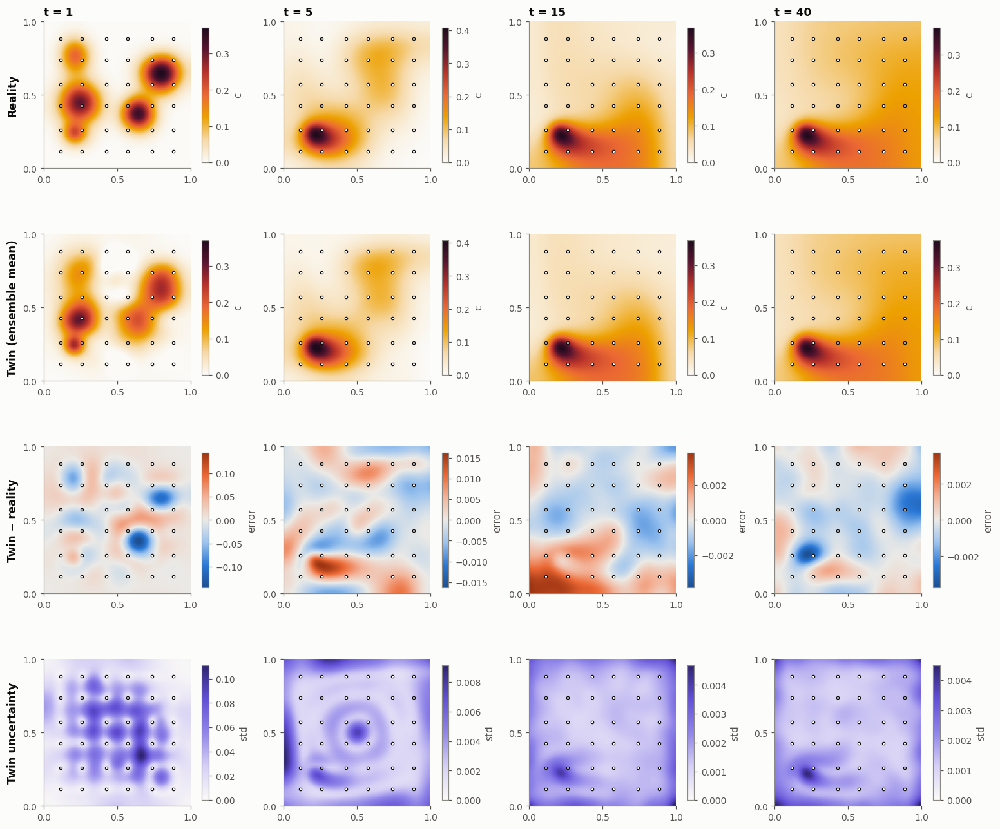

In [4]:
show = [1, 5, 15, 40]
fig, axes = plt.subplots(4, len(show), figsize=(14, 12), constrained_layout=True)
for j, i in enumerate(show):          # each column has its own scale: errors shrink by 100x over time
    vmax = truth[i].max()
    err = best["mean"][i] - truth[i]
    lim = np.abs(err).max()
    viz.field(axes[0, j], truth[i], vmin=0, vmax=vmax, label="c", title=f"t = {t_cyc[i]:.0f}")
    viz.field(axes[1, j], best["mean"][i], vmin=0, vmax=vmax, label="c")
    viz.field(axes[2, j], err, cmap=viz.DIVERGING, vmin=-lim, vmax=lim, label="error")
    viz.field(axes[3, j], best["std"][i], cmap=viz.UNCERTAINTY, vmin=0, label="std")
    for r in range(4):
        viz.sensors_2d(axes[r, j], sx, sy, s=8, linewidth=0.8)
for r, name in enumerate(["Reality", "Twin (ensemble mean)", "Twin − reality", "Twin uncertainty"]):
    axes[r, 0].set_ylabel(name, fontsize=11, color=viz.INK, fontweight="semibold")
viz.save(fig, "06_enkf_maps.png")
plt.show()

## 4. Error over time, and does the twin know how wrong it is?
A well-tuned ensemble has **spread ≈ RMSE** (dotted ≈ solid). Spread far below error means an
over-confident twin that will ignore its sensors (filter divergence).

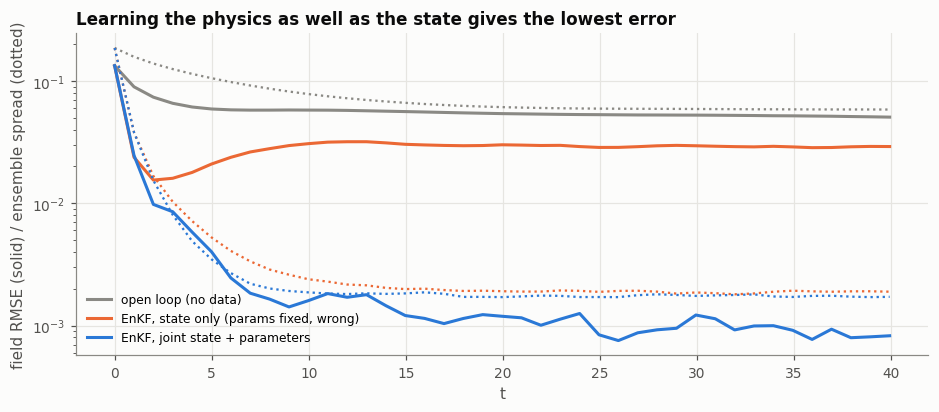

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for i, (name, r) in enumerate(runs.items()):
    col = [viz.MUTED, viz.ORANGE, viz.BLUE][i]
    ax.plot(t_cyc, r["rmse"], color=col, label=f"{name}")
    ax.plot(t_cyc, r["spread"], color=col, ls=":", lw=1.5)
ax.set(xlabel="t", ylabel="field RMSE (solid) / ensemble spread (dotted)", yscale="log",
       title="Learning the physics as well as the state gives the lowest error")
ax.legend(loc="lower left", fontsize=8)
plt.show()

Look at the orange run: its spread (≈0.002) is ~15× smaller than its actual error (≈0.03). With
the wrong physics frozen in, the ensemble is **over-confident**: it trusts its wrong model and
under-weights the sensors. Spread ≪ error is the classic symptom of model error, and a cue that
the twin needs to learn parameters (or needs more model noise).

## 5. The twin learns κ and the pump strength

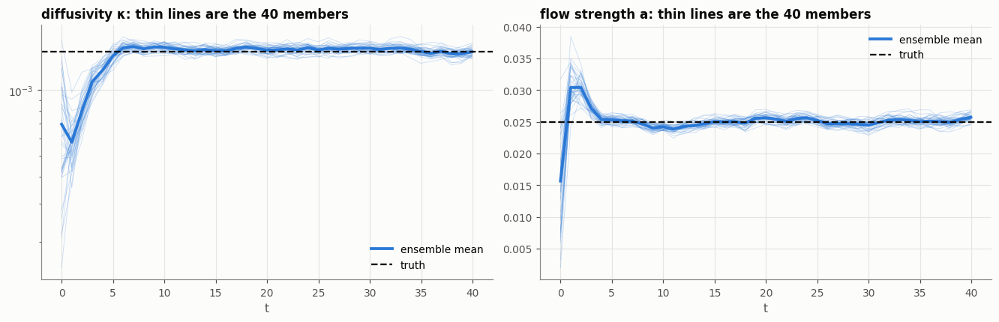

kappa: 1.50e-03 (true 1.5e-03)   a: 0.0257 (true 0.025)


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
for ax, key, true, tr, lbl in [(axes[0], "logk", KAPPA_TRUE, np.exp, "diffusivity κ"),
                               (axes[1], "flow", FLOW_TRUE, lambda v: v, "flow strength a")]:
    vals = tr(best[key])
    ax.plot(t_cyc, vals, color=viz.TWIN, lw=0.5, alpha=0.25)
    ax.plot(t_cyc, vals.mean(1), color=viz.TWIN, lw=2.5, label="ensemble mean")
    ax.axhline(true, color=viz.TRUTH, ls="--", lw=1.5, label="truth")
    ax.set(xlabel="t", title=f"{lbl}: thin lines are the 40 members")
    if key == "logk":
        ax.set_yscale("log")
    ax.legend()
plt.show()
print(f"kappa: {np.exp(best['logk'][-1]).mean():.2e} (true {KAPPA_TRUE:.1e})   "
      f"a: {best['flow'][-1].mean():.4f} (true {FLOW_TRUE})")

## 6. Localization: why a 40-member ensemble needs help
With $N=40$ samples, the estimated correlation between two distant points is pure sampling noise of
size $\sim 1/\sqrt{N}\approx0.16$. Those **spurious correlations** let a sensor in one corner
"correct" the opposite corner. **Localization** multiplies the covariance by a taper
$\rho(d)$ (Gaspari-Cohn) that goes to zero beyond a cut-off distance.

Below: the Kalman gain for one sensor, i.e. how much an innovation at that sensor moves each grid
cell, with and without localization (small ensemble, $N=15$). Then we run a full
twin with only $N=8$ members, with and without localization.

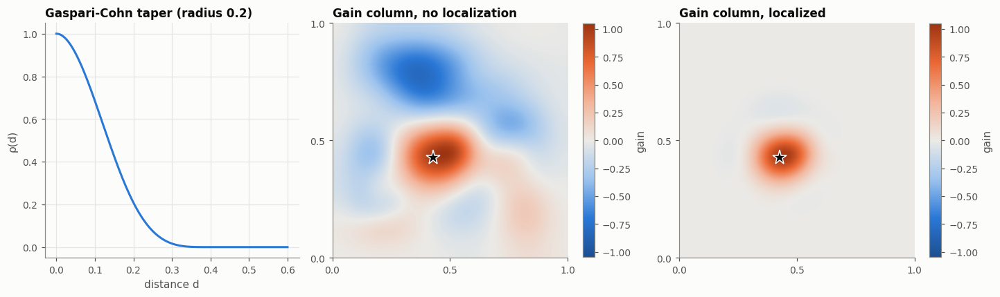

In [7]:
r_ = np.random.default_rng(5)
E = forecast(forecast(init_ensemble(15, r_), r_), r_)
j_obs = 14
gains = []
for loc in [None, 0.2]:
    A = E - E.mean(0)
    HA = A[:, obs_idx]
    PHt = A.T @ HA / 14
    if loc:
        d = np.linalg.norm(coords - coords[obs_idx[j_obs]], axis=1)
        PHt[:n_state, j_obs] *= gaspari_cohn(d / loc)
    gains.append(PHt[:n_state, j_obs].reshape(N_GRID, N_GRID) / (PHt[obs_idx[j_obs], j_obs] + sens.noise_std**2))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
dd = np.linspace(0, 0.6, 200)
axes[0].plot(dd, gaspari_cohn(dd / 0.2), color=viz.TWIN)
axes[0].set(xlabel="distance d", ylabel="ρ(d)", title="Gaspari-Cohn taper (radius 0.2)")
lim = np.abs(gains[0]).max()
for ax, g, ttl in zip(axes[1:], gains, ["Gain column, no localization", "Gain column, localized"]):
    viz.field(ax, g, cmap=viz.DIVERGING, vmin=-lim, vmax=lim, label="gain", title=ttl)
    ax.plot(sx[j_obs], sy[j_obs], "*", color=viz.INK, ms=14, mec="white")
plt.show()

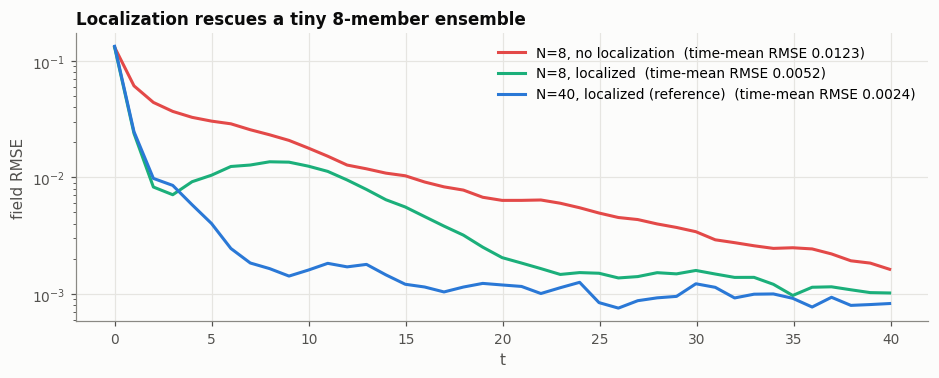

4s


In [8]:
t0 = time.time()
small = {f"N=8, {'localized' if loc else 'no localization'}": run(N=8, loc_radius=loc, seed=3)
         for loc in [None, 0.2]}
small["N=40, localized (reference)"] = best
fig, ax = plt.subplots(figsize=(10, 3.4))
for i, (name, r) in enumerate(small.items()):
    ax.plot(t_cyc, r["rmse"], color=[viz.RED, viz.AQUA, viz.BLUE][i],
            label=f"{name}  (time-mean RMSE {r['rmse'][1:].mean():.4f})")
ax.set(xlabel="t", ylabel="field RMSE", yscale="log", title="Localization rescues a tiny 8-member ensemble")
ax.legend()
plt.show()
print(f"{time.time() - t0:.0f}s")

## 7. Watch the twin converge

In [9]:
anim = viz.animate_2d([truth, best["mean"], best["std"]], t_cyc,
                      ["Reality", "Twin (ensemble mean)", "Twin uncertainty (std)"],
                      cmaps=[viz.FIELD, viz.FIELD, viz.UNCERTAINTY],
                      vlims=[(0, truth[5:].max()), (0, truth[5:].max()), (0, 0.03)], sensors=(sx, sy), size=3.4, interval=200)
HTML(anim.to_jshtml())

## Recap
| Ingredient | Why |
|---|---|
| Ensemble forecast | nonlinear model, no linearisation or adjoint needed |
| State augmentation | parameters learned from cross-covariances with observations |
| Inflation + model noise | stops the ensemble from collapsing (over-confidence) |
| Localization | removes spurious long-range correlations from small ensembles |
| Spread ≈ RMSE | the twin's uncertainty can be trusted |

**Cost:** each analysis cycle runs $N$ full simulations, the main bottleneck for big fields. The
**next notebook** compresses the field into a handful of modes so the twin runs orders of
magnitude faster.

**Exercises**
1. Use only 9 sensors (3×3). Which parameter suffers most?
2. Turn off parameter jitter and inflation. Plot spread vs RMSE: do you see filter divergence?